# Background Information - What is WiFi and how does it work?

Every radio signal is fundamentally an electromagnetic wave travelling through the air oscillating at some frequency. Different technologies get assigned different frequency ranges (mostly by international agreement) and WiFi signals are mainly around 2.4GHz. WiFi is a protocol that allows devices to wirelessly exchange data with each other. The protocol in short:
* A subcarrier is a radio wave at one specific frequency. 
* Your data starts as bits inside your phone. These bits then get grouped into small chunks (allows better information encoding) and then split across subcarriers.
* Each subcarrier gets its own ongoing stream of these chunks which are then used to transform the subcarriers amplitude and phase (based on a lookup table).
* These subcarriers then travel through the air or through walls, picking up some real-world distortion.
* The router then measures each subcarrier's actual amplitude/phase (its CSI) and decodes the information turning everything back into the original data.
* This whole technique is called Orthogonal Frequency-Divison Multplexing (OFDM). The transmission of a group of data is also called a **packet**.

Channel State Information (CSI) is data that WiFi hardware (like a router) computes as a part of its normal operations. It describes how the radio signal was distorted travelling from a transmitter to a receiver (i.e., did the signal get weaker or did its phase shift). The frequency range in which the subcarriers operate in is called a channel. So around 2.4GHz there are multiple channels which usually have a range of 20MHz. The main benefit for having multiple channels is so that your network has its own frequency space. If your neighbor is using channel 6, your WiFi would use channel 11 so that there is no interference.

## The Aim of the Report

With an understanding of how WiFi works, the aim of this report can be better understood. Research shows that when a person walks through a room their body can absorb/reflect WiFi signals which can affect CSI in a detectable way. The goal of this report is to predict human presence based on these distortions.

### Wi-Fi CSI presence detection - Stage 1 data analysis

Room4 of the IEEE DataPort *CSI Dataset for WiFi Based Human Detection* (DOI 10.21227/smn7-jb67):
empty room (label 0) vs one person present (label 1).
Each magnitude CSV = one ~70 s recording; rows = packets (time), 49 columns = subcarriers
(47 used after dropping the two band edges); no header, no timestamps.

## Setup and data location
- **JupyterHub:** upload `data_room4.zip` (plus the optional `data_room4_phase.zip` and `data_lab_static.zip`) next to this notebook; the cell below unzips them once.
- **Local repo:** uses the project's `CSV Files/` folder one level up.

In [ ]:
import glob
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from helpers import list_csv, load_raw, load_complex, load, window, split_files, iqr, summarise_folder, start_time, split_files
from constants import N_PHASE_FILES, EXPECTED_FILES, DROP_SUBCARRIERS, FIG_DIR, FILE_S, WIN_S

import os


# look for the dataset in the current working directory: 
for zip_path in sorted(glob.glob("data_*.zip")): #looks in current folder for zip files with names like data_room4.zip
    with zipfile.ZipFile(zip_path) as z:
        if not os.path.exists(z.namelist()[-1]):     # check if that file has been extracted
            z.extractall(".")  #unzip any data_*.zip in the same folder where .ipynb file lives (JupyterHub)
DATA = "CSV Files" if os.path.isdir("CSV Files") else "../CSV Files" #does a folder name CSV file exist, if yes name it CSV Files
assert os.path.isdir(DATA), "CSV Files/ not found - upload data_room4.zip next to this notebook"


# make the paths easy names
FOLDERS = {
    "empty":      f"{DATA}/room4_iqbal/Static_noperson_channel_11_20mhz/csi_magnitude_data",
    "person":     f"{DATA}/room4_iqbal/Dynamic_1_person_ch11_20mhz/csi_magnitude_data",
    # not used for training: only checked to decide what "Static" means
    "lab_static": f"{DATA}/LAB_Final Year Project/Static_Lab_ch6_20mhz/csi_magnitude_data",
}
# complex (amplitude + phase) files: only read in the phase check below, never used as features
COMPLEX_FOLDERS = {name: FOLDERS[name].replace("csi_magnitude_data", "csi_complex_data")
                   for name in ("empty", "person")} #compact way to make the path names same as above with csi_comple_data instead of csi_magnitude_data

os.makedirs(FIG_DIR, exist_ok=True)

## Helpers
This section loads the data and defines helpers for preprocessing.
1. First find & load the CSVs (list_csv, load_raw, load, load_complex)
2. Summarize signal behaviour per file (iqr, spread, summarise_folder
3. Chop recordings into fixed length windows for individual training examples
4. Organize metadata (timestamps and split data by files)

In [ ]:
#defined in helpers.py

## Inspect one file per class
Data validation before computing anything.
1. Find all the CSVs for each category
2. Confirm all files have been unzipped correctly
3. Load one representative file from "empty" and "person"
4. Visually confirm: correct shpae, no missing values, and some early on stats

In [9]:
#list_csv is being called on each folder and returning the sorted list of csv files found in it
files = {name: list_csv(folder) for name, folder in FOLDERS.items()} #.items gives you each key value pair, for name, folder unpacks  those values into variables name and folder
print({name: len(f) for name, f in files.items()}) #num of files in each

# Makes sure you have all the files: a half-finished unzip leaves too few files; if this fails, delete "CSV Files/" and re-run from the top
for name, n in EXPECTED_FILES.items():
    assert len(files[name]) in (n, 0 if name == "lab_static" else n), (name, len(files[name]))
#first of file in each folder - this is cleaned data
first = {name: load(files[name][0]) for name in ("empty", "person")}

#Print diagnostic for each sample file
for name, df in first.items():
    print(f"\n=== {name}: {len(files[name])} files, first = {os.path.basename(files[name][0])}") #header: folder name, total files, and file being inspected
    print("shape (packets, subcarriers):", df.shape)
    print("missing values:", df.isna().sum().sum())
    display(pd.DataFrame({"std": df.std(), "IQR": iqr(df)}).T.round(1))

{'empty': 10, 'person': 85, 'lab_static': 91}

=== empty: 10 files, first = csi_20241204_020632_magnitude.csv
shape (packets, subcarriers): (5405, 47)
missing values: 0


,1,2,3,4,5,6,7,8,9,10,...,38,39,40,41,42,43,44,45,46,47
std,255.6,279.0,193.9,266.0,281.0,210.6,293.1,267.0,282.1,183.2,...,14.0,19.4,18.1,18.6,53.1,17.4,18.0,15.8,12.0,15.1
IQR,9.5,9.9,10.2,10.0,8.5,9.2,9.2,9.8,11.5,10.2,...,10.1,10.5,8.8,8.5,7.5,6.7,6.7,6.6,6.2,7.5



=== person: 85 files, first = csi_20241203_223721_magnitude.csv
shape (packets, subcarriers): (10408, 47)
missing values: 0


,1,2,3,4,5,6,7,8,9,10,...,38,39,40,41,42,43,44,45,46,47
std,142.0,127.9,117.9,115.0,113.5,150.0,181.6,217.1,252.0,277.0,...,203.2,225.2,232.9,237.2,227.0,194.8,170.7,144.0,113.9,87.2
IQR,220.7,172.3,138.6,115.4,119.6,226.3,298.8,381.5,455.9,507.4,...,330.8,385.8,417.7,429.2,412.1,341.1,277.5,223.2,160.0,98.0


## Subcarrier comparison - Person vs Empty
An exploratory plot used to compare the wave form of single subcarrier from a room with a person vs. a room without a person.

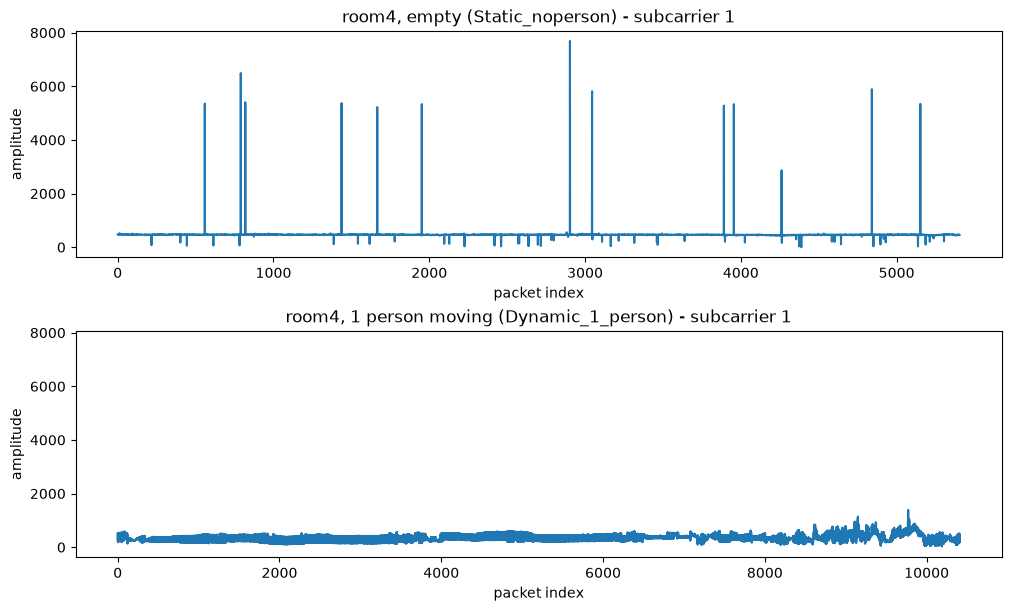

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True, constrained_layout=True)
for ax, name, title in zip(axes, ("empty", "person"),
                           ("room4, empty (Static_noperson)", "room4, 1 person moving (Dynamic_1_person)")):
    ax.plot(first[name][1])
    ax.set_title(f"{title} - subcarrier 1")
    ax.set_xlabel("packet index")
    ax.set_ylabel("amplitude")
plt.savefig(f"{FIG_DIR}/fig_raw_subcarrier1.png", dpi=150)
plt.show()

## Justifying dropping the edge-subcarriers
Checks across every file in "empty" and "person" folders whether subcarriers 0 and 48 are consistently noisier (higher IQR) than a typical subcarrier. edge_table is a summary table justifying the decision

In [11]:
#measuring across every file is subcarrier 0 or 48 consistently more variable than a typical subcarrier in the same file
ratio_rows = []
for name in ("empty", "person"):
    ratios = []
    for f in files[name]:
        r = iqr(load_raw(f))
        inner = r.drop(index=DROP_SUBCARRIERS).median()
        ratios.append((r[0] / inner, r[48] / inner))
    ratios = np.array(ratios)
    for i, sc in enumerate(DROP_SUBCARRIERS):
        ratio_rows.append({"class": name, "subcarrier": sc, "files": len(ratios),
                           "files with ratio > 1": int((ratios[:, i] > 1).sum()),
                           "median ratio": np.median(ratios[:, i]),
                           "min": ratios[:, i].min(), "max": ratios[:, i].max()})
edge_table = pd.DataFrame(ratio_rows).round(2)
edge_table.to_csv(f"{FIG_DIR}/table_edge_subcarriers.csv", index=False)
edge_table

,class,subcarrier,files,files with ratio > 1,median ratio,min,max
0,empty,0,10,10,2.29,1.31,3.13
1,empty,48,10,10,5.26,2.62,6.98
2,person,0,85,27,0.91,0.35,1.86
3,person,48,85,30,0.74,0.14,2.44


## Feature selection: why phase is not used
This checks whether CSI phase carries usable information or is it just hardware noise. Raw CSI phase from commodity Wi-Fi cards are known to carry random per-packet offsets. For the first 10 recordings of each class ("empty" and "person") using subcarriers 1-47, we compute three diagnostics per file and summarize them into one row per class.
1. Circular variance of the phase over time (0 = constant phase, 1 = uniformly random)
2. the median phase jump between consecutive packets (uniformly random phase gives pi/2 = 1.57 rad)
3. And for comparison, the relative spread of the magnitude (IQR / median).

In [12]:
phase_rows = []
for name, folder in COMPLEX_FOLDERS.items():
    complex_files = list_csv(folder)[:N_PHASE_FILES]
    if not complex_files:
        print(f"{name}: no complex files found - upload data_room4_phase.zip to run this check")
        continue
    circ_var, jump, mag_rel = [], [], []
    for f in complex_files:
        c = load_complex(f)[:, 1:48]                    # inner subcarriers, same as the features
        phase, mag = np.angle(c), np.abs(c)
        circ_var.append(np.median(1 - np.abs(np.mean(np.exp(1j * phase), axis=0))))
        jump.append(np.median(np.abs(np.angle(np.exp(1j * np.diff(phase, axis=0))))))
        q75, q25 = np.percentile(mag, [75, 25], axis=0)
        mag_rel.append(np.median((q75 - q25) / np.median(mag, axis=0)))
    phase_rows.append({"class": name, "files": len(complex_files),
                       "phase circular variance": np.median(circ_var),
                       "median phase jump (rad)": np.median(jump),
                       "magnitude IQR / median": np.median(mag_rel)})
phase_table = pd.DataFrame(phase_rows).round(3)
phase_table.to_csv(f"{FIG_DIR}/table_phase_check.csv", index=False)
phase_table

,class,files,phase circular variance,median phase jump (rad),magnitude IQR / median
0,empty,10,0.990,1.572,0.018
1,person,10,0.991,1.575,0.614


## Full-dataset spread summary and 'lab_static' label check
Here every file is loaded and as well as compute the spread. Includes a summary for each class. The code also investigates if 'lab_static' can be trusted

In [13]:
summary = {name: summarise_folder(files[name]) for name in FOLDERS if files[name]}

for name, (packets, spreads) in summary.items():
    print(f"{name:10s} files={len(spreads):3d}  median IQR min={min(spreads):6.1f}  max={max(spreads):6.1f}")

# label check: if the Lab "Static" folder was loaded, compare its spread with room4
if "lab_static" in summary:
    lab = summary["lab_static"][1]
    print(f"\nLab 'Static' range {min(lab):.1f}-{max(lab):.1f} vs room4 empty max {max(summary['empty'][1]):.1f}, "
          f"person min {min(summary['person'][1]):.1f} -> inside the person range, so 'Static' is ambiguous "
          f"(empty in a noisier room, or a still person) and the Lab folders are excluded")

empty      files= 10  median IQR min=   7.7  max=  25.4
person     files= 85  median IQR min=  67.8  max= 303.3
lab_static files= 91  median IQR min= 204.6  max= 275.8

Lab 'Static' range 204.6-275.8 vs room4 empty max 25.4, person min 67.8 -> inside the person range, so 'Static' is ambiguous (empty in a noisier room, or a still person) and the Lab folders are excluded


## Dataset statistics for room 4
This summary table combines: file counts, packet counts, duration, how many training samples after windowing, and repeat of earlier spreads for comparing "empty" vs "person" classes.

In [14]:
rows = []
for name, label in (("empty", 0), ("person", 1)):
    packets, spreads = summary[name]
    rows.append({
        "class": name,
        "label": label,
        "files": len(packets),
        "packets (total)": sum(packets),
        "duration (s, approx.)": len(packets) * FILE_S,
        "packets/s (median)": round(np.median(packets) / FILE_S),
        f"{WIN_S}-s windows (non-overlapping)": len(packets) * (FILE_S // WIN_S),
        "median IQR (min-max)": f"{min(spreads):.1f}-{max(spreads):.1f}",
    })
table = pd.DataFrame(rows)
table.to_csv(f"{FIG_DIR}/table_dataset_stats.csv", index=False)
table

,class,label,files,packets (total),"duration (s, approx.)",packets/s (median),2-s windows (non-overlapping),median IQR (min-max)
0,empty,0,10,57641,700,78,350,7.7-25.4
1,person,1,85,518122,5950,77,2975,67.8-303.3


## Train / validation / test split and data leakage check
Splits each class's files into train/val/test sets using fixed counts. The splitting is done by whole files so a single recording never gets divided across sets.

In [15]:
splits = {
    "empty":  split_files(files["empty"],  n_train=6,  n_val=2),    # 6 / 2 / 2
    "person": split_files(files["person"], n_train=51, n_val=17),   # 51 / 17 / 17
}

split_rows = []
for name, parts in splits.items():
    for part, part_files in parts.items():
        split_rows.append({
            "class": name,
            "set": part,
            "files": len(part_files),
            f"{WIN_S}-s windows": len(part_files) * (FILE_S // WIN_S),
            "first start": start_time(part_files[0]),
            "last start": start_time(part_files[-1]),
        })
split_table = pd.DataFrame(split_rows)
split_table.to_csv(f"{FIG_DIR}/table_split.csv", index=False)

# no file may appear in two sets
all_split = [f for parts in splits.values() for part_files in parts.values() for f in part_files]
assert len(all_split) == len(set(all_split)) == len(files["empty"]) + len(files["person"])
split_table

,class,set,files,2-s windows,first start,last start
0,empty,train,6,210,2024-12-04 02:06:32,2024-12-04 02:12:23
1,empty,val,2,70,2024-12-04 02:13:33,2024-12-04 02:14:43
2,empty,test,2,70,2024-12-04 02:15:53,2024-12-04 02:17:04
3,person,train,51,1785,2024-12-03 22:37:21,2024-12-03 23:35:46
4,person,val,17,595,2024-12-03 23:36:56,2024-12-03 23:55:37
5,person,test,17,595,2024-12-03 23:56:47,2024-12-04 00:15:29


## Figure (a): one 2-s window per class
Here we try to visualize a single 2-second window from the empty and person sample files as side-by-side heatmaps. The color of each square is how strong the signal is at that subcarrier.

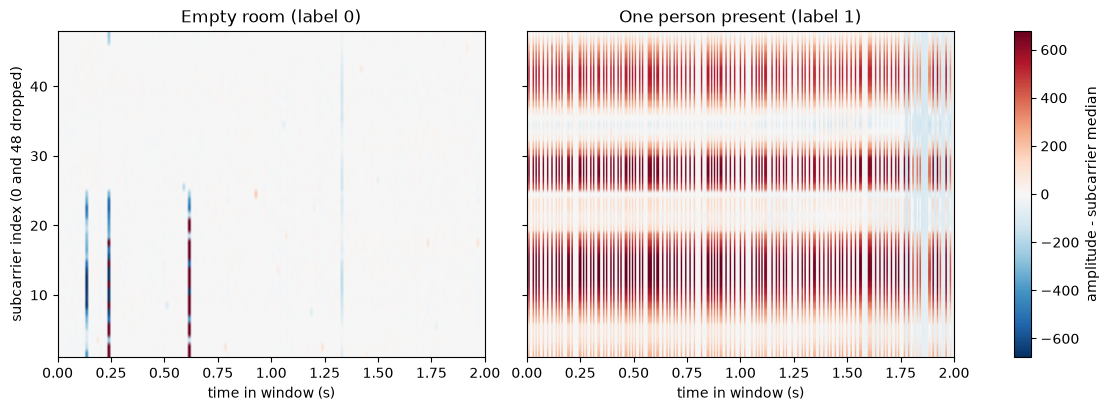

In [16]:
centred = {}
for name in ("empty", "person"):
    w = window(first[name], start_s=10)
    centred[name] = w - np.median(w, axis=0)     # different subcarries sit at differnt amplitude levels so by subtracting median every subcarriers level is 0
lim = np.percentile(np.abs(np.vstack(list(centred.values()))), 99)   # shared colour range, ignores spikes

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, name, title in zip(axes, ("empty", "person"),
                           ("Empty room (label 0)", "One person present (label 1)")):
    c = centred[name]
    im = ax.imshow(c.T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[0, WIN_S, 1, 48])
    ax.set_title(title)
    ax.set_xlabel("time in window (s)")
axes[0].set_ylabel("subcarrier index (0 and 48 dropped)")
fig.colorbar(im, ax=axes, label="amplitude - subcarrier median")
plt.savefig(f"{FIG_DIR}/fig_a_heatmap.png", dpi=150)
plt.show()

## Figure (b): spread per recording, empty vs person

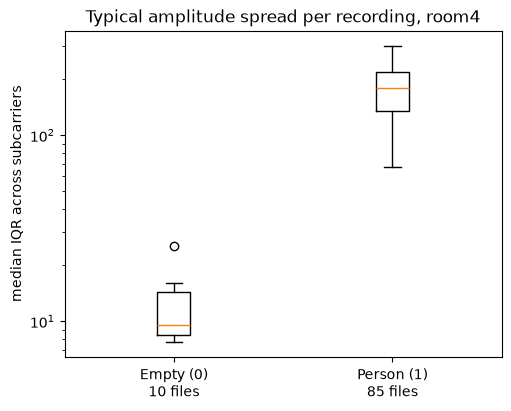

In [17]:
empty_spreads, person_spreads = summary["empty"][1], summary["person"][1]
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
ax.boxplot([empty_spreads, person_spreads])
ax.set_xticks([1, 2], [f"Empty (0)\n{len(empty_spreads)} files", f"Person (1)\n{len(person_spreads)} files"])
ax.set_ylabel("median IQR across subcarriers")
ax.set_yscale("log")          # values span about 7 to 300
ax.set_title("Typical amplitude spread per recording, room4")
plt.savefig(f"{FIG_DIR}/fig_b_spread_boxplot.png", dpi=150)
plt.show()